<a href="https://colab.research.google.com/github/Somosree-Projects/student-performance-prediction/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [112]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [113]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("student-por.csv", sep=";")

# Display the first five records
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]


In [114]:
# Display dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (649, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-

**Step 2 — Data preprocessing**

In [115]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values: 0


In [116]:
# Count duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Records: 0
Dataset Shape After Removing Duplicates: (649, 33)


In [117]:
# Display data types of all columns
print(df.dtypes)

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [118]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Identify categorical columns
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [119]:
# Select columns for outlier detection
outlier_columns = [
    "age",
    "absences",
    "G1",
    "G2",
    "G3"
]

# Store outlier counts
outlier_summary = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_summary.append({
        "Column": column,
        "Outlier Count": len(outliers)
    })

# Display outlier summary
outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df)

     Column  Outlier Count
0       age              1
1  absences             21
2        G1             16
3        G2             25
4        G3             16


In [120]:
# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Display the updated dataset
print(df_encoded.head())

print("\nDataset Shape After Encoding:", df_encoded.shape)

   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         0       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...                1               0              1           0   
1     1  ...                0               0              0           1   
2     2  ...                1               0              1           0   
3     1  ...                1               0              0           1   
4     1  ...                0               0              0           1   

   paid_yes  activities_yes  nursery_yes  higher_yes  internet

**Step 3 — Exploratory Data Analysis (EDA) and Visualization**

In [121]:
# Display statistical summary of numerical data
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
              age        Medu        Fedu  traveltime   studytime    failures  \
count  649.000000  649.000000  649.000000  649.000000  649.000000  649.000000   
mean    16.744222    2.514638    2.306626    1.568567    1.930663    0.221880   
std      1.218138    1.134552    1.099931    0.748660    0.829510    0.593235   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    1.000000    1.000000    1.000000    0.000000   
50%     17.000000    2.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  649.000000  649.000000  649.000000  649.000000  649.000000  649.000000   
mean     3.930663    3.180277    3.184900    1.502311    2.280431    3.536210   
std   

In [122]:
# Calculate average marks
print("Average First Period Grade (G1):", df["G1"].mean())
print("Average Second Period Grade (G2):", df["G2"].mean())
print("Average Final Grade (G3):", df["G3"].mean())

# Find highest and lowest final grades
print("\nHighest Final Grade:", df["G3"].max())
print("Lowest Final Grade:", df["G3"].min())

Average First Period Grade (G1): 11.399075500770415
Average Second Period Grade (G2): 11.570107858243452
Average Final Grade (G3): 11.906009244992296

Highest Final Grade: 19
Lowest Final Grade: 0


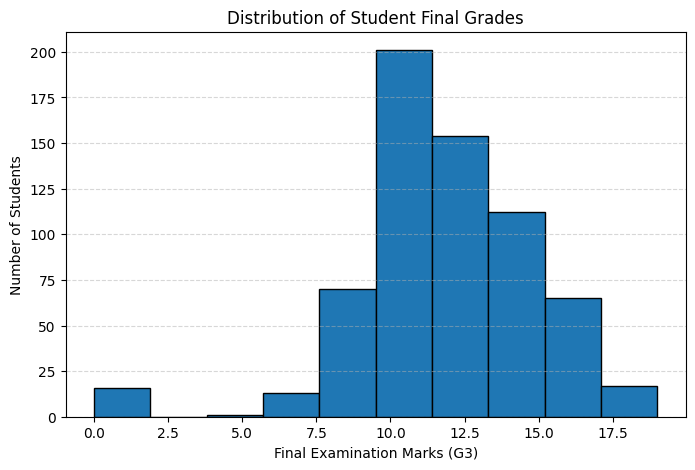

In [123]:
# Distribution of final examination marks

plt.figure(figsize=(8, 5))

plt.hist(
    df["G3"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Examination Marks (G3)")
plt.ylabel("Number of Students")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

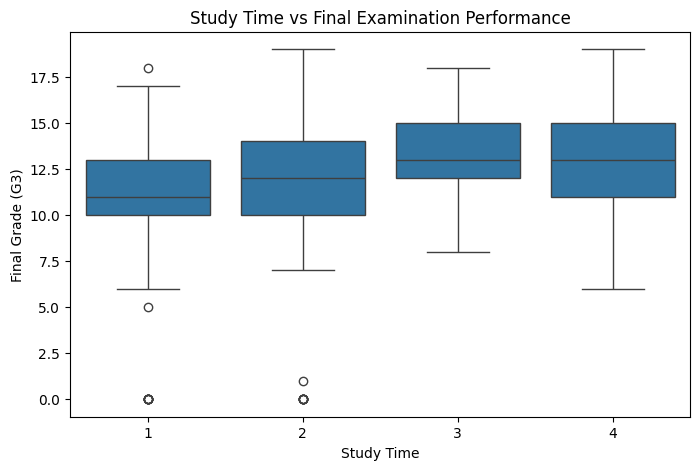

In [124]:
# Study time vs final examination marks

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="studytime",
    y="G3",
    data=df
)

plt.title("Study Time vs Final Examination Performance")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")

plt.show()

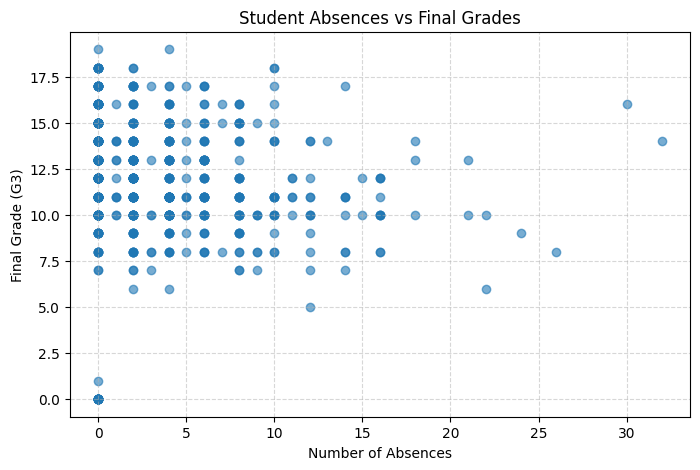

In [125]:
# Absences vs final examination marks

plt.figure(figsize=(8, 5))

plt.scatter(
    df["absences"],
    df["G3"],
    alpha=0.6,
    marker="o"
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [126]:
# Calculate correlation between numerical variables
correlation = df.select_dtypes(include=["int64", "float64"]).corr()

# Display correlation with final grade
print("Correlation with Final Grade (G3):")
print(correlation["G3"].sort_values(ascending=False))

Correlation with Final Grade (G3):
G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64


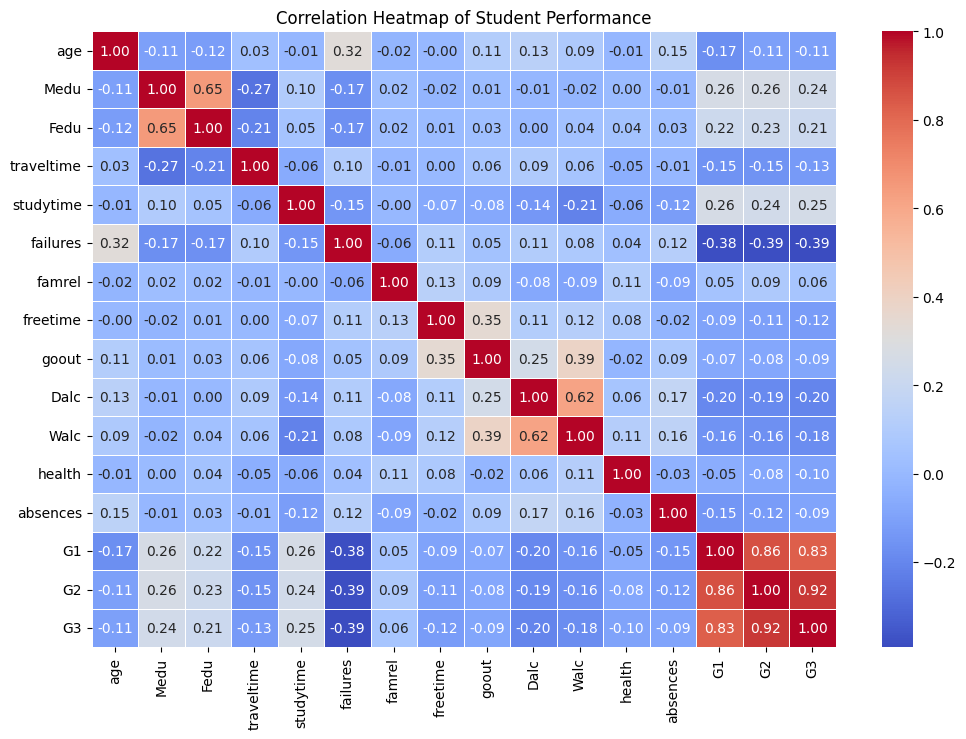

In [127]:
# Correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance")
plt.show()

**Step 4 — Machine Learning Model Development**

In [128]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

# Import preprocessing libraries
from sklearn.preprocessing import StandardScaler

# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [129]:
# Separate input features and target variable
X = df_encoded.drop("G3", axis=1)
y = df_encoded["G3"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (519, 41)
Testing Data: (130, 41)


**Model 1 — Linear Regression**

**Objective:** Predict students' final examination marks.

In [130]:
# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict final examination marks
linear_predictions = linear_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, linear_predictions)
mse = mean_squared_error(y_test, linear_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_predictions)

print("========== LINEAR REGRESSION ==========")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

========== LINEAR REGRESSION ==========
Mean Absolute Error: 0.77
Mean Squared Error: 1.48
Root Mean Squared Error: 1.21
R2 Score: 0.85


**Model 2 — Logistic Regression**

**Objective:** Predict whether a student will Pass or Fail.

In [131]:
# Create Pass/Fail target
y_pass = (df["G3"] >= 10).astype(int)

# Split the data
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X,
    y_pass,
    test_size=0.20,
    random_state=42,
    stratify=y_pass
)

# Scale the features
scaler_lr = StandardScaler()

X_train_scaled = scaler_lr.fit_transform(X_train_lr)
X_test_scaled = scaler_lr.transform(X_test_lr)

# Create Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train_scaled, y_train_lr)

# Predict Pass/Fail
logistic_predictions = logistic_model.predict(X_test_scaled)

# Evaluate the model
print("========== LOGISTIC REGRESSION ==========")
print("Accuracy:", round(
    accuracy_score(y_test_lr, logistic_predictions) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_lr,
    logistic_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
))

========== LOGISTIC REGRESSION ==========
Accuracy: 90.77 %

Confusion Matrix:
[[ 13   7]
 [  5 105]]

Classification Report:
              precision    recall  f1-score   support

        Fail       0.72      0.65      0.68        20
        Pass       0.94      0.95      0.95       110

    accuracy                           0.91       130
   macro avg       0.83      0.80      0.82       130
weighted avg       0.90      0.91      0.91       130



**Model 3 — K-Nearest Neighbors (KNN)**

**Objective:** Classify students based on the academic patterns of similar students.

In [132]:
# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train_lr)

# Predict Pass/Fail
knn_predictions = knn_model.predict(X_test_scaled)

# Evaluate the model
print("========== K-NEAREST NEIGHBORS ==========")
print("Accuracy:", round(
    accuracy_score(y_test_lr, knn_predictions) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, knn_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_lr,
    knn_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
))

========== K-NEAREST NEIGHBORS ==========
Accuracy: 82.31 %

Confusion Matrix:
[[  2  18]
 [  5 105]]

Classification Report:
              precision    recall  f1-score   support

        Fail       0.29      0.10      0.15        20
        Pass       0.85      0.95      0.90       110

    accuracy                           0.82       130
   macro avg       0.57      0.53      0.52       130
weighted avg       0.77      0.82      0.79       130



**Model 4 — K-Means Clustering**

**Objective:** Divide students into three academic performance groups:

**1.** High Performing

**2.** Average

**3.** Academically At-Risk

In [133]:
# Select features for clustering
cluster_data = df[
    ["studytime", "absences", "failures", "G1", "G2"]
]

# Scale the data
scaler_kmeans = StandardScaler()

cluster_scaled = scaler_kmeans.fit_transform(cluster_data)

# Create K-Means model
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Perform clustering
df["Cluster"] = kmeans_model.fit_predict(cluster_scaled)

# Calculate average final grade for each cluster
cluster_summary = df.groupby("Cluster").agg(
    Average_G3=("G3", "mean"),
    Student_Count=("G3", "count")
)

# Identify cluster performance order
sorted_clusters = cluster_summary["Average_G3"].sort_values().index

# Assign performance labels based on average final grades
cluster_labels = {
    sorted_clusters[0]: "Academically At-Risk",
    sorted_clusters[1]: "Average",
    sorted_clusters[2]: "High Performing"
}

# Add performance groups
df["Performance_Group"] = df["Cluster"].map(cluster_labels)

# Display results
print("========== K-MEANS CLUSTERING ==========")
print(df[["G1", "G2", "G3", "Cluster", "Performance_Group"]].head(10))

print("\nCluster Summary:")
print(df.groupby("Performance_Group").agg(
    Student_Count=("G3", "count"),
    Average_Final_Grade=("G3", "mean")
))

========== K-MEANS CLUSTERING ==========
   G1  G2  G3  Cluster Performance_Group
0   0  11  11        0           Average
1   9  11  11        0           Average
2  12  13  12        2   High Performing
3  14  14  14        2   High Performing
4  11  13  13        2   High Performing
5  12  12  13        0           Average
6  13  12  13        2   High Performing
7  10  13  13        0           Average
8  15  16  17        2   High Performing
9  12  12  13        2   High Performing

Cluster Summary:
                      Student_Count  Average_Final_Grade
Performance_Group                                       
Academically At-Risk             97             8.319588
Average                         287            10.825784
High Performing                 265            14.388679


**Step 5 — Model Optimization and Cross-Validation**

In [134]:
# Import optimization and cross-validation libraries
from sklearn.model_selection import GridSearchCV, cross_val_score

In [135]:
# Perform 5-fold cross-validation
linear_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("========== LINEAR REGRESSION OPTIMIZATION ==========")
print("Cross Validation Scores:", linear_cv_scores)
print("Average R2 Score:", round(linear_cv_scores.mean(), 3))

========== LINEAR REGRESSION OPTIMIZATION ==========
Cross Validation Scores: [0.75327197 0.7397694  0.82061432 0.8549464  0.80095376]
Average R2 Score: 0.794


In [136]:
# Define parameter values
logistic_parameters = {
    "C": [0.01, 0.1, 1, 10, 100]
}

# Create GridSearchCV
logistic_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    logistic_parameters,
    cv=5,
    scoring="accuracy"
)

# Train the optimized model
logistic_grid.fit(X_train_scaled, y_train_lr)

# Get best model
best_logistic_model = logistic_grid.best_estimator_

print("========== LOGISTIC REGRESSION OPTIMIZATION ==========")
print("Best Parameters:", logistic_grid.best_params_)
print("Best Cross Validation Accuracy:",
      round(logistic_grid.best_score_ * 100, 2), "%")

========== LOGISTIC REGRESSION OPTIMIZATION ==========
Best Parameters: {'C': 0.1}
Best Cross Validation Accuracy: 91.91 %


In [137]:
# Define KNN parameter values
knn_parameters = {
    "n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "weights": ["uniform", "distance"]
}

# Create GridSearchCV
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_parameters,
    cv=5,
    scoring="accuracy"
)

# Train optimized KNN model
knn_grid.fit(X_train_scaled, y_train_lr)

# Get best model
best_knn_model = knn_grid.best_estimator_

print("========== KNN OPTIMIZATION ==========")
print("Best Parameters:", knn_grid.best_params_)
print("Best Cross Validation Accuracy:",
      round(knn_grid.best_score_ * 100, 2), "%")

========== KNN OPTIMIZATION ==========
Best Parameters: {'n_neighbors': 7, 'weights': 'distance'}
Best Cross Validation Accuracy: 87.67 %


In [138]:
# Import silhouette score
from sklearn.metrics import silhouette_score

# Store silhouette scores
silhouette_scores = []

# Test different cluster numbers
for k in range(2, 6):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    score = silhouette_score(cluster_scaled, labels)

    silhouette_scores.append(score)

    print("Clusters:", k, "Silhouette Score:", round(score, 3))

# Find best cluster number
best_k = range(2, 6)[
    np.argmax(silhouette_scores)
]

print("\nBest Number of Clusters:", best_k)

Clusters: 2 Silhouette Score: 0.272
Clusters: 3 Silhouette Score: 0.262
Clusters: 4 Silhouette Score: 0.271
Clusters: 5 Silhouette Score: 0.269

Best Number of Clusters: 2


In [139]:
# Predict using optimized models
best_logistic_predictions = best_logistic_model.predict(X_test_scaled)

best_knn_predictions = best_knn_model.predict(X_test_scaled)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test_lr,
    best_logistic_predictions
) * 100

knn_accuracy = accuracy_score(
    y_test_lr,
    best_knn_predictions
) * 100

# Display comparison
print("========== OPTIMIZED MODEL COMPARISON ==========")

print("Optimized Logistic Regression Accuracy:",
      round(logistic_accuracy, 2), "%")

print("Optimized KNN Accuracy:",
      round(knn_accuracy, 2), "%")

========== OPTIMIZED MODEL COMPARISON ==========
Optimized Logistic Regression Accuracy: 90.0 %
Optimized KNN Accuracy: 83.08 %


**Step 6 — Final Results and Student Prediction System**

In [140]:
# Calculate Linear Regression performance
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Calculate optimized classification performance
logistic_accuracy = accuracy_score(
    y_test_lr,
    best_logistic_model.predict(X_test_scaled)
) * 100

knn_accuracy = accuracy_score(
    y_test_lr,
    best_knn_model.predict(X_test_scaled)
) * 100

# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "KNN",
        "K-Means"
    ],
    "Evaluation": [
        f"R2 Score: {linear_r2:.3f}",
        f"Accuracy: {logistic_accuracy:.2f}%",
        f"Accuracy: {knn_accuracy:.2f}%",
        f"Silhouette Score: {max(silhouette_scores):.3f}"
    ]
})

print("========== MODEL PERFORMANCE COMPARISON ==========")
print(model_comparison)

========== MODEL PERFORMANCE COMPARISON ==========
                 Model               Evaluation
0    Linear Regression          R2 Score: 0.849
1  Logistic Regression         Accuracy: 90.00%
2                  KNN         Accuracy: 83.08%
3              K-Means  Silhouette Score: 0.272


In [141]:
# Compare actual and predicted marks
prediction_results = pd.DataFrame({
    "Actual Marks": y_test,
    "Predicted Marks": linear_predictions
})

prediction_results["Predicted Marks"] = (
    prediction_results["Predicted Marks"].round(2)
)

print("========== FINAL MARKS PREDICTION ==========")
print(prediction_results.head(10))

========== FINAL MARKS PREDICTION ==========
     Actual Marks  Predicted Marks
636            19            18.40
220            12            11.83
594            18            18.56
429            11            10.81
72             11            11.74
448            17            16.52
181            18            17.69
131             8             9.21
231            10            10.99
277            11            10.53


In [142]:
# Predict pass/fail probability
pass_probabilities = best_logistic_model.predict_proba(
    X_test_scaled
)

# Get predicted classes
pass_predictions = best_logistic_model.predict(
    X_test_scaled
)

# Display prediction results
pass_results = pd.DataFrame({
    "Actual Result": [
        "Pass" if value == 1 else "Fail"
        for value in y_test_lr
    ],
    "Predicted Result": [
        "Pass" if value == 1 else "Fail"
        for value in pass_predictions
    ],
    "Pass Probability (%)": (
        pass_probabilities[:, 1] * 100
    ).round(2)
})

print("========== PASS/FAIL PREDICTION ==========")
print(pass_results.head(10))

========== PASS/FAIL PREDICTION ==========
  Actual Result Predicted Result  Pass Probability (%)
0          Pass             Pass                 97.98
1          Pass             Pass                 96.38
2          Pass             Pass                 99.61
3          Pass             Pass                 99.87
4          Pass             Fail                 27.87
5          Fail             Fail                 14.02
6          Fail             Fail                 47.42
7          Pass             Pass                 99.92
8          Pass             Pass                 99.98
9          Pass             Pass                 86.14


In [143]:
# Create academic risk categories
def identify_risk(marks):

    if marks < 10:
        return "High Risk"

    elif marks < 14:
        return "Medium Risk"

    else:
        return "Low Risk"


# Assign risk levels
prediction_results["Academic Risk"] = (
    prediction_results["Predicted Marks"].apply(identify_risk)
)

print("========== ACADEMIC RISK ANALYSIS ==========")
print(
    prediction_results[
        ["Actual Marks", "Predicted Marks", "Academic Risk"]
    ].head(10)
)

========== ACADEMIC RISK ANALYSIS ==========
     Actual Marks  Predicted Marks Academic Risk
636            19            18.40      Low Risk
220            12            11.83   Medium Risk
594            18            18.56      Low Risk
429            11            10.81   Medium Risk
72             11            11.74   Medium Risk
448            17            16.52      Low Risk
181            18            17.69      Low Risk
131             8             9.21     High Risk
231            10            10.99   Medium Risk
277            11            10.53   Medium Risk


In [144]:
# Count students in each performance group
performance_counts = df["Performance_Group"].value_counts()

print("========== STUDENT PERFORMANCE SEGMENTATION ==========")
print(performance_counts)

========== STUDENT PERFORMANCE SEGMENTATION ==========
Performance_Group
Average                 287
High Performing         265
Academically At-Risk     97
Name: count, dtype: int64


In [145]:
# Extract feature importance from Linear Regression
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

# Calculate absolute coefficient values
feature_importance["Importance"] = (
    feature_importance["Coefficient"].abs()
)

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("========== IMPORTANT PERFORMANCE FACTORS ==========")
print(feature_importance.head(10))

========== IMPORTANT PERFORMANCE FACTORS ==========
           Feature  Coefficient  Importance
14              G2     0.858834    0.858834
27    Fjob_teacher    -0.535769    0.535769
26   Fjob_services    -0.530630    0.530630
29    reason_other    -0.418710    0.418710
20     Mjob_health     0.343000    0.343000
25      Fjob_other    -0.330553    0.330553
32  guardian_other     0.322548    0.322548
24     Fjob_health    -0.308570    0.308570
15       school_MS    -0.304551    0.304551
23    Mjob_teacher     0.302682    0.302682


In [146]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
importance_result = permutation_importance(
    linear_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2"
)

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean
})

# Sort features
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("========== IMPORTANT PERFORMANCE FACTORS ==========")
print(feature_importance.head(10))

========== IMPORTANT PERFORMANCE FACTORS ==========
              Feature  Importance
14                 G2    1.319917
13                 G1    0.026321
25         Fjob_other    0.009693
26      Fjob_services    0.005655
1                Medu    0.004503
27       Fjob_teacher    0.003976
5            failures    0.003883
3          traveltime    0.003176
11             health    0.002685
30  reason_reputation    0.002578


In [147]:
# Find a student present in both test sets
common_indices = X_test.index.intersection(X_test_lr.index)

# Select one student
student_id = common_indices[0]

# Get student information from the original dataset
student_data = X.loc[[student_id]]

# Predict final examination marks
predicted_marks = linear_model.predict(student_data)[0]

# Scale the student data
student_scaled = scaler_lr.transform(student_data)

# Predict Pass/Fail
pass_prediction = best_logistic_model.predict(student_scaled)[0]

# Calculate pass probability
pass_probability = best_logistic_model.predict_proba(
    student_scaled
)[0][1]

# Predict using KNN
knn_prediction = best_knn_model.predict(student_scaled)[0]

# Get clustering features using the same student index
student_cluster_data = df.loc[
    student_id,
    ["studytime", "absences", "failures", "G1", "G2"]
]

# Convert the selected row into a DataFrame
student_cluster_data = student_cluster_data.to_frame().T

# Scale clustering features
student_cluster_scaled = scaler_kmeans.transform(
    student_cluster_data
)

# Predict performance group
cluster_number = kmeans_model.predict(
    student_cluster_scaled
)[0]

performance_group = cluster_labels[cluster_number]

# Identify academic risk
risk_level = identify_risk(predicted_marks)

# Display results
print("\n========== STUDENT PERFORMANCE PREDICTION ==========")

print("Student Record ID:", student_id)

print("Actual Final Marks:", df.loc[student_id, "G3"])

print("Predicted Final Marks:", round(predicted_marks, 2))

print("Pass/Fail Prediction:",
      "Pass" if pass_prediction == 1 else "Fail")

print("Pass Probability:", round(pass_probability * 100, 2), "%")

print("KNN Prediction:",
      "Pass" if knn_prediction == 1 else "Fail")

print("Academic Risk Level:", risk_level)

print("Performance Group:", performance_group)

print("====================================================")


========== STUDENT PERFORMANCE PREDICTION ==========
Student Record ID: 636
Actual Final Marks: 19
Predicted Final Marks: 18.4
Pass/Fail Prediction: Pass
Pass Probability: 99.99 %
KNN Prediction: Pass
Academic Risk Level: Low Risk
Performance Group: High Performing


**Step 7 — Final Data Visualizations and Project Results**

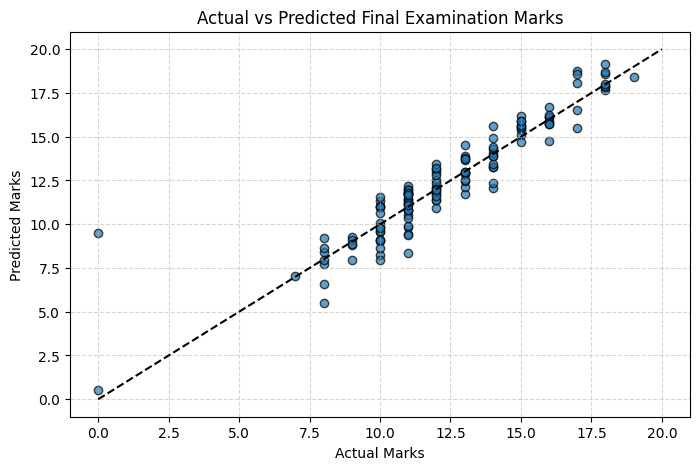

In [148]:
# Compare actual and predicted marks
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_predictions,
    marker="o",
    alpha=0.7,
    edgecolor="black"
)

# Draw the ideal prediction line
plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="black"
)

plt.title("Actual vs Predicted Final Examination Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.grid(linestyle="--", alpha=0.5)
plt.show()

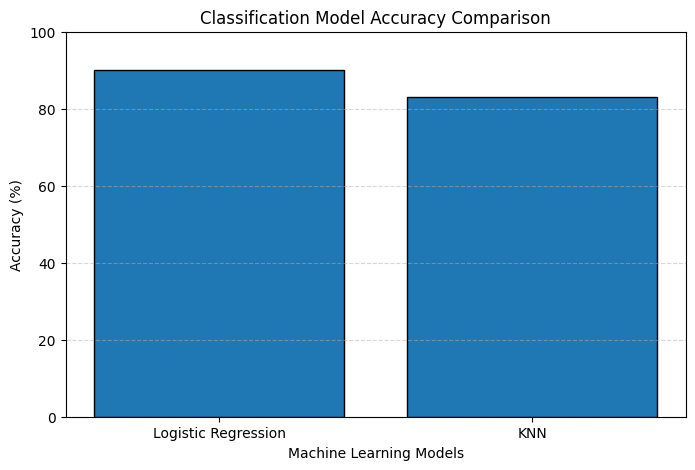

In [149]:
# Prepare model accuracy values
model_names = [
    "Logistic Regression",
    "KNN"
]

model_accuracies = [
    logistic_accuracy,
    knn_accuracy
]

# Plot model accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    model_accuracies,
    edgecolor="black"
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

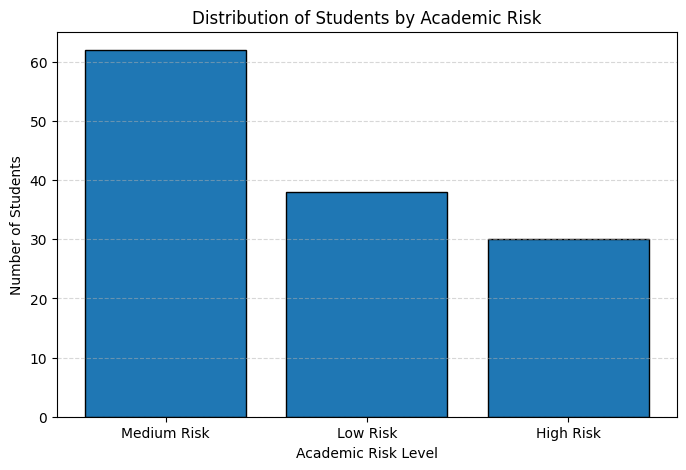

In [150]:
# Count students by academic risk
risk_counts = prediction_results["Academic Risk"].value_counts()

# Plot risk distribution
plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Students by Academic Risk")
plt.xlabel("Academic Risk Level")
plt.ylabel("Number of Students")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

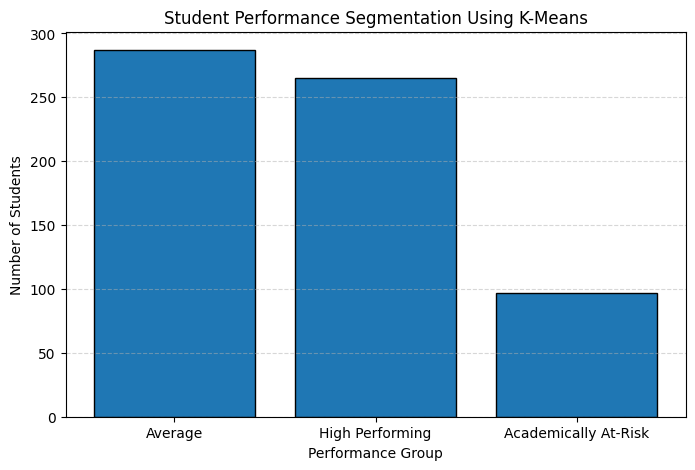

In [151]:
# Count students in each performance group
performance_counts = df["Performance_Group"].value_counts()

# Plot performance groups
plt.figure(figsize=(8, 5))

plt.bar(
    performance_counts.index,
    performance_counts.values,
    edgecolor="black"
)

plt.title("Student Performance Segmentation Using K-Means")
plt.xlabel("Performance Group")
plt.ylabel("Number of Students")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

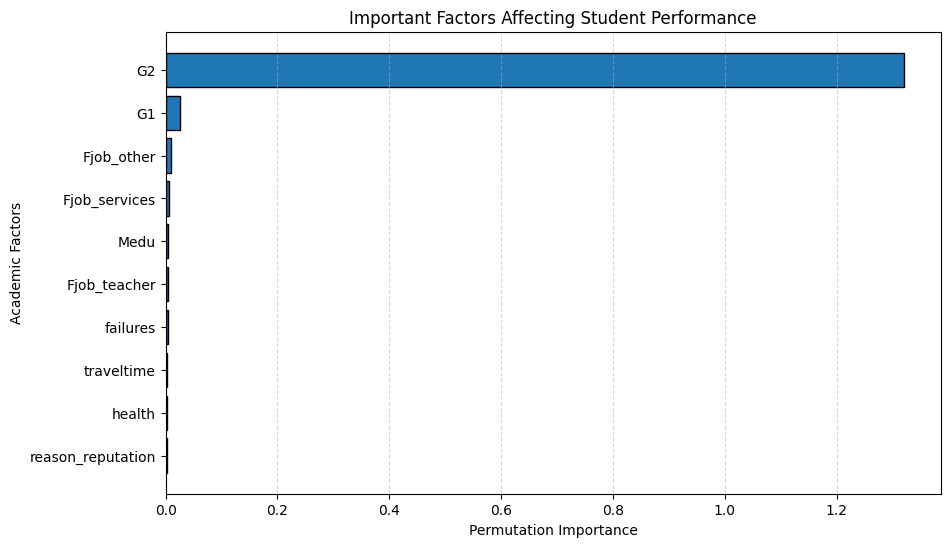

In [152]:
# Select the top 10 important factors
top_features = feature_importance.head(10)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    edgecolor="black"
)

plt.title("Important Factors Affecting Student Performance")
plt.xlabel("Permutation Importance")
plt.ylabel("Academic Factors")

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [153]:
# Display final project summary

print("\n==============================================")
print(" STUDENT PERFORMANCE PREDICTION AND")
print(" ACADEMIC RISK ANALYSIS")
print("==============================================")

print("\nDataset Information")
print("Total Students:", len(df))
print("Total Features:", df.shape[1])

print("\nMachine Learning Models")
print("1. Linear Regression")
print("2. Logistic Regression")
print("3. K-Nearest Neighbors")
print("4. K-Means Clustering")

print("\nModel Performance")

print("Linear Regression R2 Score:",
      round(linear_r2, 3))

print("Linear Regression MAE:",
      round(linear_mae, 2))

print("Logistic Regression Accuracy:",
      round(logistic_accuracy, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy, 2), "%")

print("\nStudent Performance Groups")
print(performance_counts)

print("\nAcademic Risk Distribution")
print(risk_counts)

print("\nProject Completed Successfully!")
print("==============================================")


 STUDENT PERFORMANCE PREDICTION AND
 ACADEMIC RISK ANALYSIS

Dataset Information
Total Students: 649
Total Features: 35

Machine Learning Models
1. Linear Regression
2. Logistic Regression
3. K-Nearest Neighbors
4. K-Means Clustering

Model Performance
Linear Regression R2 Score: 0.849
Linear Regression MAE: 0.77
Logistic Regression Accuracy: 90.0 %
KNN Accuracy: 83.08 %

Student Performance Groups
Performance_Group
Average                 287
High Performing         265
Academically At-Risk     97
Name: count, dtype: int64

Academic Risk Distribution
Academic Risk
Medium Risk    62
Low Risk       38
High Risk      30
Name: count, dtype: int64

Project Completed Successfully!


In [154]:
# Save prediction results
prediction_results.to_csv(
    "student_prediction_results.csv",
    index=False
)

# Save model comparison
model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

# Save student performance segmentation
df.to_csv(
    "student_performance_analysis.csv",
    index=False
)

print("Final result files saved successfully!")

Final result files saved successfully!
